# 3 · PM feature decisions: BeanBox's "perfect" churn model

**What you practise (from the feature-engineering lecture):**
- The **snapshot rule**: a feature may only use information that exists *before* the moment we predict.
- **Hunting a leak** in a "too good" result.
- The **four tests** every feature must pass: *available · same definition · allowed · useful*.
- One honest **recipe** (`Pipeline`) and fair comparisons with **cross-validation**.
- Turning domain knowledge into **yes/no flags** that a simple model can use.
- **Unknown categories** in production, a **feature spec**, and a recommendation.

## ☕ The case: BeanBox

**BeanBox** sends freshly roasted coffee beans to subscribers every month. About **1 in 4 subscribers cancels** in a given month.

**Nora**, Head of Retention, has a team that can **call 100 subscribers per month** with a personal offer (a free bag, a pause option). She asks:

*"On the 1st of every month, can a model tell us **which 100 subscribers to call**, the ones most likely to cancel this month?"*

- **Snapshot:** we score everyone on the morning of **1 November**.
- **Label:** `cancelled` = 1 if the subscriber cancelled **between 1 and 30 November**.
- **Kai**, the data scientist, has just sent his first model…

> 📌 The data is **synthetic** (made for this course) but realistic: 2,000 subscribers, 14 columns. Same ideas as TeamFlow, different product. Tomorrow you work on TeamFlow's real data.

> **How this notebook works**
> - Run the cells **from top to bottom** with `Shift + Enter`.
> - ▶️ **Run** cells work as they are.
> - ✏️ **Your turn** cells contain `___` (three underscores). Replace each `___` with your answer, then run the cell.
> - ✅ **Check** cells tell you whether you got it right. If a check fails, read the hint, fix the cell above and run both again.
> - 🧠 **Think** cells ask a PM question. Double-click the answer cell below it and write 1–3 sentences.
> - If you see `NameError: name '___' is not defined`, a blank is still empty.
> - Stuck? The `solutions/` folder has the same notebook, solved.

## Step 0 · Load the tools and the data

In [1]:
# ▶️ Run: libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

subscribers = pd.read_csv("data/beanbox_subscribers.csv")
subscribers.head()

,subscriber_id,months_subscribed,plan,bags_per_month,signup_channel,country,app_opens_last_4w,deliveries_skipped_90d,support_contacts_90d,avg_bag_rating,lifetime_spend_eur,days_since_last_order,exit_survey_done,cancelled
0,BB-10001,9,starter,1,google_ads,AT,7,0,0,NaN,100.25,17,0,0
1,BB-10002,7,classic,2,instagram,DE,2,0,1,NaN,183.60,1,0,0
2,BB-10003,6,classic,3,instagram,DE,1,0,0,NaN,251.34,64,1,1
3,BB-10004,10,starter,1,friend_referral,NL,8,0,0,NaN,103.87,10,0,0
4,BB-10005,6,classic,2,friend_referral,NL,2,0,0,3.0,172.31,20,0,0


| column | meaning (all as of the 1 Nov snapshot, **unless stated**) |
|---|---|
| `subscriber_id` | ID |
| `months_subscribed` | months since sign-up |
| `plan` | `starter` < `classic` < `barista` (bigger, pricier beans) |
| `bags_per_month` | bags in each delivery |
| `signup_channel` | instagram, google_ads, friend_referral, podcast (empty = tracking blocked) |
| `country` | DE, AT, CH, NL |
| `app_opens_last_4w` | app opens in the 4 weeks before 1 Nov |
| `deliveries_skipped_90d` | deliveries skipped in the 90 days before 1 Nov |
| `support_contacts_90d` | support contacts in the 90 days before 1 Nov |
| `avg_bag_rating` | average star rating the subscriber gave their bags (empty = never rated) |
| `lifetime_spend_eur` | total spent since sign-up |
| `days_since_last_order` | days since the last order, **computed by Kai's export script on 30 Nov** |
| `exit_survey_done` | 1 = the subscriber filled in the exit survey |
| **`cancelled`** | **target**: 1 = cancelled between 1 and 30 Nov |

In [2]:
# ✏️ Your turn: what share of subscribers cancelled in November?
# Hint: `cancelled` is 0/1, so its average IS the share of 1s.
cancel_share = subscribers["cancelled"].mean()
print("Cancelled in November:", round(cancel_share, 3))

Cancelled in November: 0.242


In [3]:
# ✅ Check
assert abs(cancel_share - 0.242) < 0.001, "Use .mean()"
print("✅ Correct: 24.2% cancelled, about 1 in 4. If Nora's team called 100 RANDOM subscribers, they'd reach about 24 cancellers.")

✅ Correct: 24.2% cancelled, about 1 in 4. If Nora's team called 100 RANDOM subscribers, they'd reach about 24 cancellers.


## Step 1 · Split first (the test set is next month's subscribers)

In [4]:
# ▶️ Run: 75% to learn from, 25% kept aside as the final exam (stratified: same cancel share in both)
X = subscribers.drop(columns="cancelled")
y = subscribers["cancelled"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print("train:", len(X_train), "| test:", len(X_test), "of which cancelled:", y_test.sum())

train: 1500 | test: 500 of which cancelled: 121


## Step 2 · Kai's report

Kai: *"I used **every** column. Look at this!"*

The cell below defines Kai's **recipe** (fill gaps → scale numbers, one-hot the words, plan in its real order, then logistic regression). **Just run it**: you'll look inside in Step 5.

In [ ]:


def build_model(number_columns):
    # number_columns = the list of numeric columns to use as features.
    # The function returns a complete, UNFITTED model (preparation + logistic regression).

    # --- Recipe 1: numeric columns ---
    numbers = Pipeline([
        # Step 1: fill missing values with the MEDIAN of that column (learned from the training data).
        # add_indicator=True also adds a 0/1 column "was this value missing?" for each column that
        # had missing values, because missingness itself can carry information (e.g. no rating given).
        ("fill", SimpleImputer(strategy="median", add_indicator=True)),
        # Step 2: scale every column to mean 0 and std 1, so no column dominates just because
        # its numbers are bigger (e.g. lifetime_spend_eur vs. bags_per_month).
        ("scale", StandardScaler()),
    ])

    # --- Recipe 2: text columns without a natural order (signup_channel, country) ---
    words = Pipeline([
        # Step 1: fill missing values with the MOST FREQUENT value of that column.
        ("fill", SimpleImputer(strategy="most_frequent")),
        # Step 2: one-hot encoding = one new 0/1 column per category.
        # handle_unknown="ignore": a category never seen in training (new country) gets all zeros
        # at prediction time instead of raising an error.
        ("one_hot", OneHotEncoder(handle_unknown="ignore")),
    ])

    # --- Recipe 3: the plan column, which has a natural order ---
    plan = Pipeline([
        # Step 1: turn the text into numbers in the GIVEN order: starter=0, classic=1, barista=2.
        # (One-hot would throw away the fact that barista is "more" than starter.)
        ("order", OrdinalEncoder(categories=[["starter", "classic", "barista"]])),
        # Step 2: scale the 0/1/2 like the other numeric columns.
        ("scale", StandardScaler()),
    ])

    # ColumnTransformer = apply each recipe to ITS columns and put the results side by side.
    prep = ColumnTransformer([
        ("numbers", numbers, list(number_columns)),         # numeric recipe -> the chosen numeric columns
        ("words", words, ["signup_channel", "country"]),    # text recipe    -> these two columns
        ("plan", plan, ["plan"]),                           # ordered recipe -> the plan column
    ])  # every column that is not listed here is dropped (this is the default)

    # Final model: first the preparation, then logistic regression.
    # max_iter=1000 gives the solver enough iterations to converge.
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=1000))])


def cv_auc(number_columns, X_data=X_train):
    """5-fold cross-validation AUC on the TRAINING data only (the 'rehearsal exams')."""
    # cross_val_score cuts the training data into 5 parts. For each part it:
    #   1. builds a fresh model with build_model(...)
    #   2. fits it (including imputing and scaling) on the other 4 parts
    #   3. scores it with ROC AUC on the held-out part
    # .mean() averages the 5 scores into one number.
    # For a classifier, cv=5 automatically keeps the class ratio in each part (stratified).
    # The test set is never touched, so it stays a fair final exam.
    return cross_val_score(build_model(number_columns), X_data, y_train, cv=5, scoring="roc_auc").mean()


# The numeric columns that can be used as features.
# You can pass all of them or a smaller list to cv_auc(...) and compare the AUC scores
# to see which features help.
all_numbers = ["months_subscribed", "bags_per_month", "app_opens_last_4w", "deliveries_skipped_90d",
               "support_contacts_90d", "avg_bag_rating", "lifetime_spend_eur",
               "days_since_last_order", "exit_survey_done"]
print("Recipe ready.")   # this cell only defines things, it trains nothing yet

Recipe ready.


In [6]:
# ▶️ Run: Kai's model, trained on the training rows and scored ONCE on the test rows
kai_model = build_model(all_numbers).fit(X_train, y_train)
kai_auc = roc_auc_score(y_test, kai_model.predict_proba(X_test)[:, 1])
print(f"📈 Kai's test AUC: {kai_auc:.3f}")

📈 Kai's test AUC: 1.000


AUC 1.00 means **every** canceller got a higher risk score than **every** subscriber who stayed. For human behaviour like cancelling a subscription, that almost never happens honestly.

🚩 **Red flag #4: a feature that's too good.** A score that looks too good is a *question*, not a celebration.

## Step 3 · Hunt the leak

PM question #1: **"Which single column helps most?"** The cell below scores each number column **on its own** (AUC of that one column, training data only).

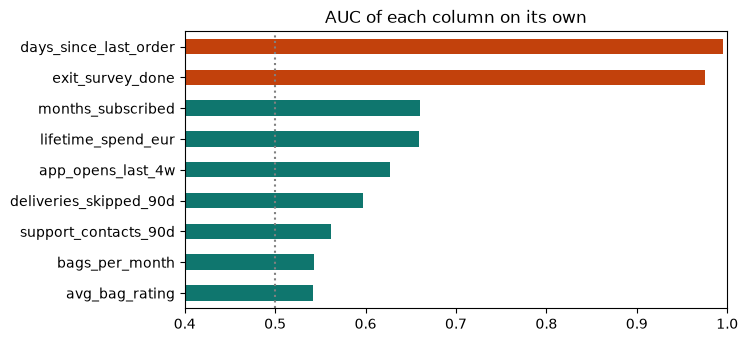

days_since_last_order     0.995
exit_survey_done          0.975
months_subscribed         0.661
lifetime_spend_eur        0.660
app_opens_last_4w         0.627
deliveries_skipped_90d    0.597
support_contacts_90d      0.561
bags_per_month            0.543
avg_bag_rating            0.542
dtype: float64

In [8]:
# ▶️ Run: how well does each column ALONE rank cancellers above stayers? (0.5 = coin flip, 1.0 = perfect)
def one_column_auc(column):
    values = X_train[column].fillna(X_train[column].median())
    auc = roc_auc_score(y_train, values)
    return max(auc, 1 - auc)            # direction doesn't matter here

alone = pd.Series({c: one_column_auc(c) for c in all_numbers}).sort_values()
alone.plot.barh(figsize=(7, 3.6), color=["#c2410c" if v > 0.9 else "#0f766e" for v in alone])
plt.axvline(0.5, color="grey", ls=":"); plt.xlim(0.4, 1.0); plt.title("AUC of each column on its own")
plt.show()
alone.round(3).sort_values(ascending=False)

In [ ]:
# ✏️ Your turn: which TWO columns are suspicious? (write the column names)
suspicious = ["___", "___"]

In [ ]:
# ✅ Check
assert sorted(c.strip() for c in suspicious) == ["days_since_last_order", "exit_survey_done"], \
    "Look for the two bars far above all the others."
print("✅ Correct: each of them ALONE is almost perfect. Real churn signals are never that clean.")

🧠 **Think:** PM question #2: **when is each of these two columns filled in?** Would we have them on the morning of 1 November? Which of the two leaks is *sneakier*, and why?

**✍️ Your answer:** *double-click here and write 1–3 sentences.*

In [ ]:
# ✏️ Your turn: remove both leaks from the number columns
honest_numbers = [c for c in all_numbers if c not in ___]
honest_cv = cv_auc(honest_numbers)
print("Columns kept:", honest_numbers)
print(f"Honest cross-validated AUC: {honest_cv:.3f}")

In [ ]:
# ✅ Check
assert "exit_survey_done" not in honest_numbers and "days_since_last_order" not in honest_numbers
assert 0.68 < honest_cv < 0.74
print(f"✅ From 1.00 to {honest_cv:.2f}. Less exciting, but this is what the model can really do on 1 November.")

## Step 4 · The four tests (Activity A, BeanBox edition)

Before any column goes in, it must pass **four tests, in this order**:

| test | question |
|---|---|
| ⏱ **Available?** | Does it exist *before* the prediction moment, every time we score? |
| 📏 **Same definition?** | Is it computed the same way in training and in production (window, date, unit)? |
| ⚖️ **Allowed?** | Are we permitted and justified to use it (documented purpose, fair, what users would expect)? |
| 📈 **Useful?** | Does it improve results on validation data, and is it worth maintaining? |

Why this order? **A leak always looks useful.** Check usefulness last.

Give each candidate a verdict: `"use"` (as is), `"fix"` (define or transform first), `"leak"` (future information) or `"dont"` (not allowed / not justified).

In [ ]:
# ✏️ Your turn: your verdict for each candidate column
verdicts = {
    "months_subscribed":     "___",   # months since sign-up, as of 1 Nov
    "app_opens_last_4w":     "___",   # window is written down: 4 weeks before 1 Nov
    "lifetime_spend_eur":    "___",   # an all-time total: what happens to it as people stay longer?
    "avg_bag_rating":        "___",   # empty for more than half of the subscribers
    "days_since_last_order": "___",   # counted up to 30 Nov by Kai's export script
    "exit_survey_done":      "___",  # filled in while cancelling
    "country":               "___",   # DE, AT, CH, NL … and Belgium launches next month
    "gender":                "___",  # not in the data yet. Kai asks: "Shall I pull it from the CRM?"
}

In [ ]:
# ✅ Check: compare with the answer key (some cards are grey zones: two answers accepted)
key = {
    "months_subscribed": ({"use"}, "Known on 1 Nov, clearly defined."),
    "app_opens_last_4w": ({"use"}, "Window is fixed (4 weeks before the snapshot)."),
    "lifetime_spend_eur": ({"fix"}, "Grows with tenure by definition. Use spend per month, or spend in the last 90 days."),
    "avg_bag_rating": ({"fix"}, "Missing ≠ 0. Fill with the median AND keep a 'never rated' flag."),
    "days_since_last_order": ({"fix", "leak"}, "Leaks as computed (30 Nov). Fix: count up to the snapshot date."),
    "exit_survey_done": ({"leak"}, "Exists only after cancelling."),
    "country": ({"fix", "use"}, "One-hot, plan for unknown countries, check results per country (fairness)."),
    "gender": ({"dont"}, "No demonstrated need, fairness + privacy questions. Exception only with documented purpose + legal review."),
}
assert set(verdicts) == set(key) and all(v in {"use", "fix", "leak", "dont"} for v in verdicts.values()), \
    "Use only 'use', 'fix', 'leak' or 'dont' for every card."
matches = 0
for column, (accepted, reason) in key.items():
    ok = verdicts[column] in accepted
    matches += ok
    print(f"{'✅' if ok else '🤔'} {column:22s} you: {verdicts[column]:5s} key: {'/'.join(sorted(accepted)):9s} {reason}")
print(f"\n{matches} of 8 match the key. Disagree with a 🤔? Good: write down your argument for the stand-up.")

From now on we use only columns that pass the tests **today**. `lifetime_spend_eur` waits until its definition is fixed (it's mostly "tenure in disguise" anyway).

In [ ]:
# ▶️ Run: our honest starting point
model_numbers = [c for c in honest_numbers if c != "lifetime_spend_eur"]
base_cv = cv_auc(model_numbers)
print("Number columns:", model_numbers)
print(f"Cross-validated AUC: {base_cv:.3f}")

## Step 5 · Look inside the recipe

The same recipe runs in training, in cross-validation, and later in production. Click the boxes in the diagram to open them.

In [ ]:
# ▶️ Run: scikit-learn draws the recipe
build_model(model_numbers)

In [ ]:
# ✏️ Your turn: read the recipe
branch_for_country = "___"        # which branch ("numbers", "words" or "plan") handles `country`?
rating_fill_strategy = "___"     # how are the gaps in avg_bag_rating filled?
rating_gets_a_flag = ___           # does the recipe also add a "was missing" column? (True / False)

In [ ]:
# ✅ Check
assert branch_for_country == "words" and rating_fill_strategy == "median" and rating_gets_a_flag is True, \
    "Look at the helper in Step 2: 'words' gets signup_channel and country; numbers use median + add_indicator=True."
print("✅ Correct: 'never rated' becomes its own 0/1 column. Missing ≠ zero, and missing can be a signal.")

🧠 **Think:** why is it important that the fill → scale → encode steps live **inside** the pipeline, rather than being done once on the whole table before cross-validation?

**✍️ Your answer:** *double-click here and write 1–3 sentences.*

## Step 6 · Domain knowledge → yes/no flags

Logistic regression gives each column **one straight-line effect**: "each extra month lowers the risk by the same amount". But churn often has **jumps**. Let's look at the training data.

In [ ]:
# ▶️ Run: cancel rate by months subscribed (TRAINING rows only)
train = X_train.assign(cancelled=y_train)
months_groups = pd.cut(train["months_subscribed"], [0, 1, 2, 3, 4, 5, 6, 9, 12, 24, 48])
train.groupby(months_groups, observed=True)["cancelled"].agg(cancel_rate="mean", subscribers="size").round(3)

In [ ]:
# ✏️ Your turn: up to how many months is a subscriber "new" (clearly higher risk)?
new_cutoff = ___

In [ ]:
# ▶️ Run: cancel rate by app opens in the last 4 weeks (TRAINING rows only)
opens_groups = pd.cut(train["app_opens_last_4w"], [-1, 0, 1, 2, 3, 5, 10, 40])
train.groupby(opens_groups, observed=True)["cancelled"].agg(cancel_rate="mean", subscribers="size").round(3)

In [ ]:
# ✏️ Your turn: up to how many app opens is a subscriber "inactive"?
inactive_cutoff = ___

In [ ]:
# ✅ Check
assert new_cutoff == 3, "Where does the cancel rate drop sharply? Between 3 and 4 months."
assert inactive_cutoff == 1, "Where does the cancel rate drop sharply? Between 1 and 2 opens."
print("✅ Correct: ≤ 3 months and ≤ 1 app open are where the risk jumps.")

In [ ]:
# ▶️ Run: add the two flags (fixed rules, all inputs as of 1 Nov) and compare with cross-validation
def add_flags(table):
    return table.assign(is_new=(table["months_subscribed"] <= new_cutoff).astype(int),
                        is_inactive=(table["app_opens_last_4w"] <= inactive_cutoff).astype(int))

X_train_flags, X_test_flags = add_flags(X_train), add_flags(X_test)

In [ ]:
# ✏️ Your turn: add the flag columns to the number columns
cv_new = cv_auc(model_numbers + ["___"], X_train_flags)
cv_both = cv_auc(model_numbers + ["is_new", "___"], X_train_flags)
print(f"honest model, no flags ... {base_cv:.3f}")
print(f"+ is_new ................. {cv_new:.3f}")
print(f"+ is_new + is_inactive ... {cv_both:.3f}")

In [ ]:
# ✅ Check
assert cv_both > cv_new > base_cv, "Add 'is_new' in the first line and 'is_inactive' in the second."
print(f"✅ Same model, same settings, two extra yes/no columns: {base_cv:.3f} → {cv_both:.3f}.")

> 🔍 **Honesty note:** we picked the cut-offs by looking at *all* training rows, and then cross-validated on those same rows. Strictly, the cut-offs should be re-learned inside each fold. In the lecture we checked this on TeamFlow and the cut-offs came out identical. Most importantly: **the test set has not been touched for any choice.**

🧠 **Think:** the model already has `months_subscribed`. Why does an extra `is_new` column help?

**✍️ Your answer:** *double-click here and write 1–3 sentences.*

## Step 7 · The final exam: test set, used once

Now, and only now, we score the 500 held-out subscribers. Nora doesn't care about AUC: she cares about **how many cancellers her team reaches with 100 calls**.

In [ ]:
# ▶️ Run: fit both versions on ALL training rows, score the test rows once
before = build_model(model_numbers).fit(X_train_flags, y_train)
after = build_model(model_numbers + ["is_new", "is_inactive"]).fit(X_train_flags, y_train)

results = {}
for name, model in [("without flags", before), ("with flags", after)]:
    scores = model.predict_proba(X_test_flags)[:, 1]
    top_100 = np.argsort(-scores)[:100]                     # the 100 highest-risk subscribers
    results[name] = {"test AUC": round(roc_auc_score(y_test, scores), 3),
                     "cancellers in top 100": int(y_test.to_numpy()[top_100].sum())}
results = pd.DataFrame(results).T.astype({"cancellers in top 100": int})
results

In [ ]:
# ✏️ Your turn: what share of Nora's 100 calls (with flags) reaches someone who would really cancel?
caught_with_flags = results.loc["with flags", "cancellers in top 100"]
call_precision = caught_with_flags / ___
print(f"{call_precision:.0%} of the calls reach a real canceller (random calling: about 24%).")

In [ ]:
# ✅ Check
assert abs(call_precision - caught_with_flags / 100) < 1e-9, "Divide by the number of calls: 100."
print(f"✅ Correct. Same team, same 100 calls: {results.iloc[0, 1]} → {caught_with_flags} cancellers reached.")

In [ ]:
# ▶️ Run: can Nora understand the model? The biggest weights (number columns are scaled, word columns are 0/1)
names = after.named_steps["prep"].get_feature_names_out()
weights = pd.Series(after.named_steps["model"].coef_[0], index=names)
weights.index = weights.index.str.replace("numbers__|words__|plan__", "", regex=True)
weights.sort_values(key=abs, ascending=False).head(8).round(2)

🧠 **Think:** write the model's story for Nora in **one sentence** she could repeat to her team.

**✍️ Your answer:** *double-click here and write 1–3 sentences.*

## Step 8 · Production surprise: Belgium 🇧🇪

On 1 December the model scores the next batch. Marketing launched BeanBox in **Belgium** last week, so some subscribers have `country = "BE"`, a value the encoder has never seen.

In [ ]:
# ▶️ Run: six subscribers from the December batch
december = pd.DataFrame({
    "subscriber_id": ["BB-20001", "BB-20002", "BB-20003", "BB-20004", "BB-20005", "BB-20006"],
    "months_subscribed": [1, 14, 2, 7, 1, 30], "plan": ["starter", "classic", "starter", "barista", "classic", "classic"],
    "bags_per_month": [1, 2, 1, 3, 2, 2], "signup_channel": ["instagram", "friend_referral", np.nan, "podcast", "instagram", "google_ads"],
    "country": ["BE", "DE", "BE", "AT", "DE", "CH"], "app_opens_last_4w": [0, 9, 1, 6, 3, 12],
    "deliveries_skipped_90d": [0, 0, 1, 0, 0, 1], "support_contacts_90d": [1, 0, 2, 0, 0, 0],
    "avg_bag_rating": [np.nan, 4.5, np.nan, 4.0, np.nan, 5.0],
})
december_scores = after.predict_proba(add_flags(december))[:, 1]
december.assign(risk=december_scores.round(2))[["subscriber_id", "country", "months_subscribed", "app_opens_last_4w", "risk"]]

No error: the recipe uses `OneHotEncoder(handle_unknown="ignore")`, so a Belgian subscriber gets **0 in every country column** ("none of the countries I know"). Scoring continues, but nobody knows how good the scores are for Belgium. That has to be **visible**.

In [ ]:
# ✏️ Your turn: a tiny monitoring check. What SHARE of December's subscribers has an unknown country?
known_countries = set(X_train["country"].unique())
unknown_share = (~december["country"].isin(known_countries)).___()
print(f"Unknown country: {unknown_share:.0%} of the batch")

In [ ]:
# ✅ Check
assert abs(unknown_share - 2 / 6) < 1e-9, "True/False values: their .mean() is the share of True."
print("✅ Correct: 2 of 6 (33%). In a real batch you'd log this number every day and alert above a threshold.")

🧠 **Think (PM decision):** Belgium will grow fast. Should the model **fail loudly** on unknown countries, or **keep scoring and alert**? Who gets the alert, and when do we retrain?

**✍️ Your answer:** *double-click here and write 1–3 sentences.*

## Step 9 · Your PM artefact: a feature spec

A feature spec is a short, written agreement about one input: a **user story for data**. Each line answers one of the four tests. Write the spec for **`is_inactive`**.

**✍️ Your spec (double-click to edit):**

| line | your answer |
|---|---|
| **Name** | `is_inactive` |
| **Definition** | ✍️ |
| **Source · owner** | ✍️ |
| **Available when?** | ✍️ |
| **Missing rule** | ✍️ |
| **Allowed?** | ✍️ |
| **Monitor** | ✍️ |

## Step 10 · Your recommendation for Nora

🧠 **Think:** ship, pilot or improve? Write 3–4 sentences: what the model does, how well (in Nora's terms), the biggest risk, and the next step.

**✍️ Your answer:** *double-click here and write 1–3 sentences.*

## ✅ Check your understanding

1. A model reports AUC 1.00. What are the three questions you ask first?
2. Why did we compare the flags with **cross-validation** and not with the test set?
3. What does a pipeline guarantee, and what can it *not* guarantee?

**Your answers to 1–3:**

**✍️ Your answer:** *double-click here and write 1–3 sentences.*

### 🎉 Well done! Tomorrow: TeamFlow's real data, your own churn model, and a ship-or-not recommendation for Maya.